In [1]:
# Setting up Libraries and packages

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Colorblind-friendly palette
orange = "#E69F00"
blue = "#00468B"

# Data source
source_note = "Source: 120 Years of Olympic History (Kaggle)"

In [2]:
# Load results exported from SQLite

medals = pd.read_csv("olympic_medal_totals.csv")
participation = pd.read_csv("olympic_womens_participation.csv")

# Preview both datasets
print("Olympic Medal Totals")
display(medals.head(10))

print("Women's Participation")
display(participation.head(10))

Olympic Medal Totals


,country,gold,silver,bronze,total_medals
0,USA,1131,901,791,2823
1,Russia,727,600,589,1916
2,Germany,578,592,596,1766
3,UK,289,320,310,919
4,France,264,286,329,879
5,Italy,256,225,241,722
6,Sweden,200,215,242,657
7,China,240,185,173,598
8,Australia,156,174,201,531
9,Hungary,178,156,176,510


Women's Participation


,Year,total_athletes,women,women_pct
0,1896,176,0,0.0
1,1900,1224,23,1.9
2,1904,650,6,0.9
3,1906,841,6,0.7
4,1908,2024,44,2.2
5,1912,2409,53,2.2
6,1920,2676,78,2.9
7,1924,3256,156,4.8
8,1928,3247,312,9.6
9,1932,1922,201,10.5


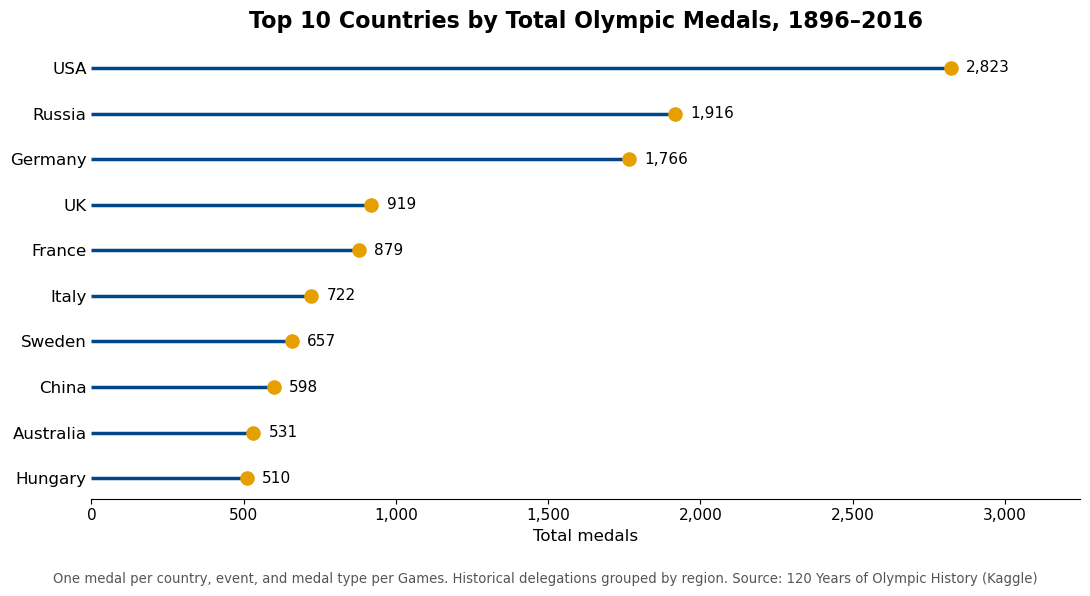

In [3]:
# Lollipop chart: Top 10 medal-winning countries

medals = medals.sort_values("total_medals", ascending=False)
fig, ax = plt.subplots(figsize=(11, 6))

ax.hlines(medals["country"], 0, medals["total_medals"], color=blue, linewidth=2.5)
ax.scatter(medals["total_medals"], medals["country"], color=orange, s=90, zorder=3)

for country, total in zip(medals["country"], medals["total_medals"]):
    ax.text(total + 50, country, f"{total:,}", va="center", fontsize=11)

ax.invert_yaxis()
ax.set_xlim(0, medals["total_medals"].max() * 1.15)
ax.set_xlabel("Total medals", fontsize=12)
ax.set_title("Top 10 Countries by Total Olympic Medals, 1896–2016",
             fontsize=16, fontweight="bold", pad=14)

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))
ax.tick_params(axis="y", length=0, labelsize=12)
ax.tick_params(axis="x", labelsize=11)
ax.spines[["top", "right", "left"]].set_visible(False)

fig.text(0.5, 0.02,
         "One medal per country, event, and medal type per Games. "
         "Historical delegations grouped by region. " + source_note,
         ha="center", fontsize=9.5, color="#555555")

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig("medal_lollipop.png", dpi=200, bbox_inches="tight")
plt.show()

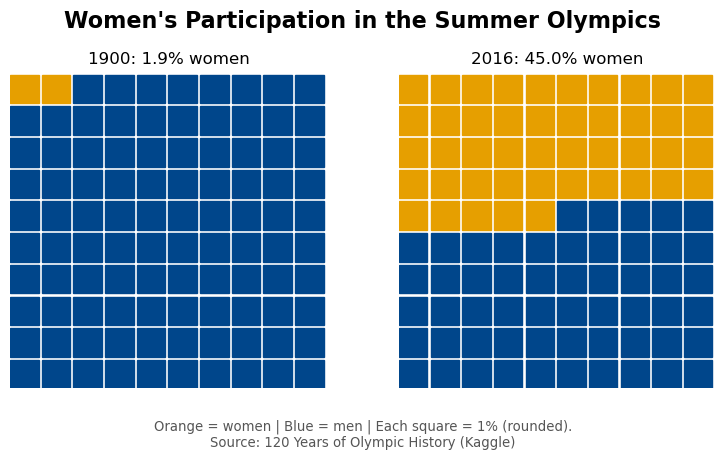

In [4]:
# Waffle chart: Women's participation, 1900 vs. 2016

fig, axes = plt.subplots(1, 2, figsize=(8, 4.8))

for ax, year in zip(axes, [1900, 2016]):
    pct = participation.loc[participation["Year"] == year, "women_pct"].iloc[0]

    for i in range(100):
        color = orange if i < round(pct) else blue
        ax.add_patch(plt.Rectangle((i % 10, 9 - i // 10),
                     0.9, 0.9, color=color))

    ax.set(xlim=(0, 10), ylim=(0, 10), aspect="equal",
           title=f"{year}: {pct:.1f}% women")
    ax.axis("off")

fig.suptitle("Women's Participation in the Summer Olympics",
             fontsize=16, fontweight="bold", y=0.95)

fig.text(0.5, 0.04,
         "Orange = women | Blue = men | Each square = 1% (rounded).\n"
         + source_note,
         ha="center", fontsize=9.5, color="#555555")

fig.subplots_adjust(left=0.04, right=0.96, top=0.82, bottom=0.16, wspace=0.12)
plt.savefig("olympic-womens-waffle.png", dpi=200, bbox_inches="tight")
plt.show()